In [ ]:
# In this tutorial we will discuss 2D and 3D data sets in Galactic and Equatorial coordinates
 

In this Tutorial we will walkthrough a visual analysis of the Small Magellanic Cloud(SMC) using HI 21cm emission and a Herschel 250 micron map.

In [3]:
!pip install spectral_cube

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [spectral_cube]0m [spectral_cube]o]


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

import astropy.units as u
from astropy.utils.data import download_file
from astropy.io import fits  # We use fits to open the actual data file

from astropy.utils import data

from spectral_cube import SpectralCube

from astroquery.esasky import ESASky
from astroquery.utils import TableList
from astropy.wcs import WCS
from reproject import reproject_interp

data.conf.remote_timeout = 60

/home/user/miniconda3/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Neutral gas emission from the Magellanic Clouds refers to radio waves naturally emitted by un-ionized (neutral) atomic hydrogen gas (\(H\,\small\text{I}\)) contained within and stripped from the Large and Small Magellanic Clouds. 

Because neutral hydrogen does not emit visible light, astronomers map this gas using radio telescopes. This emission is one of the most critical tools for studying how galaxies interact and evolve.

In [5]:
# Download the HI Fits Cube
# Downloads the HI data in a fits file format
hi_datafile = download_file(
    "http://data.astropy.org/tutorials/FITS-cubes/reduced_TAN_C14.fits",
    cache=True,
    show_progress=True,
)

In [6]:
hi_data= fits.open(hi_datafile) # Opens the FITS file reading
cube = SpectralCube.read(hi_data) # Initiate a SpectralCube
hi_data.close() # Close the Fits file- we alread read it 


If we already have the fits file downloaded in the computer, then use the following line instead.



In [ ]:
#cube = SpectralCube.read('path_to_data_file/TAN_C14.fits')

In [7]:
print(cube)

SpectralCube with shape=(450, 150, 150) and unit=K:
 n_x:    150  type_x: GLON-TAN  unit_x: deg    range:   286.727203 deg:  320.797623 deg
 n_y:    150  type_y: GLAT-TAN  unit_y: deg    range:   -50.336450 deg:  -28.401234 deg
 n_s:    450  type_s: VRAD      unit_s: m / s  range:  -598824.534 m / s:  600409.133 m / s


The file has three axes, Galactic Longitude(x), Galactic Latitude(y), and a spectral axis in terms of a LSR Velocity(z-listed as s with (spectral_cube))



With this cube, units of data in the cube are temperatures(K).

SpectralCube has a quicklook() method which can give a handy sneak-peek preview of the data. It is useful when you just need to glance at a slice or spectrum without knowing any other information.

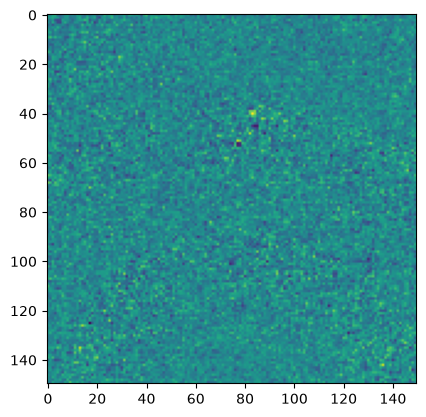

In [15]:
# Slicing the cube along the spectral axis, and display a quick image 
cube[
    378, :, :
].quicklook() 

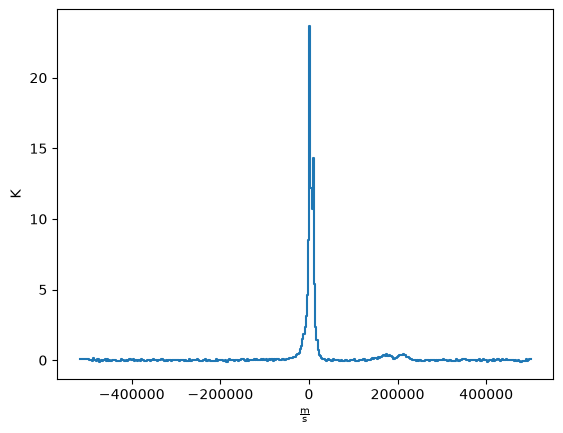

In [9]:
# Extracting a single spectrum through the data cube
cube[:, 75, 75].quicklook()


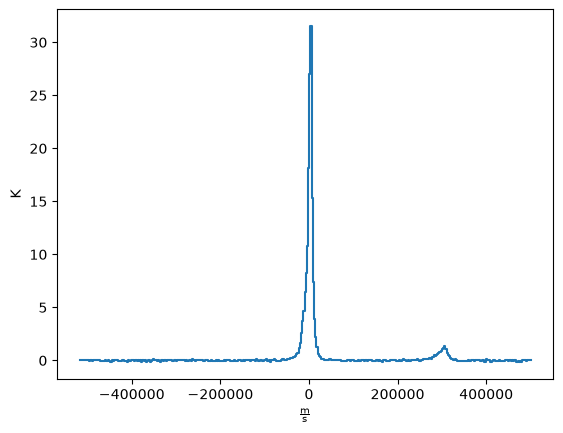

In [20]:
cube[:, 140, 140].quicklook()

In [21]:
# Making a smallar cube, focusing on the magellanic Clouds
# for extracting world coordinates from the cube using the .world()

# Creating a sub_cube

lat_range= [-46, -40] * u.deg
lon_range= [306, 295] * u.deg

# Create a sub_cube cut to these coordinates

sub_cube = cube.subcube(
    xlo=lon_range[0], xhi=lon_range[1], ylo= lat_range[0], yhi=lat_range[1]

)

print(sub_cube)




SpectralCube with shape=(450, 38, 57) and unit=K:
 n_x:     57  type_x: GLON-TAN  unit_x: deg    range:   294.113498 deg:  306.009028 deg
 n_y:     38  type_y: GLAT-TAN  unit_y: deg    range:   -46.014280 deg:  -40.027398 deg
 n_s:    450  type_s: VRAD      unit_s: m / s  range:  -598824.534 m / s:  600409.133 m / s


In [22]:
# we don't really need data from such a large velocity range so let's just extract a little slab.

sub_cube_slab = sub_cube.spectral_slab(-300.0 * u.km/u.s, 300.0 * u.km/ u.s )
print(sub_cube_slab)


SpectralCube with shape=(226, 38, 57) and unit=K:
 n_x:     57  type_x: GLON-TAN  unit_x: deg    range:   294.113498 deg:  306.009028 deg
 n_y:     38  type_y: GLAT-TAN  unit_y: deg    range:   -46.014280 deg:  -40.027398 deg
 n_s:    226  type_s: VRAD      unit_s: m / s  range:  -299683.842 m / s:  301268.441 m / s


In [25]:
# Moment Maps
# These maps helps to study data cubes. A Moment is a weighted integral along an axis(typically the Spectral Axis) that can give information
#about the total intensity (or column density), mean velocity, or velocity dispersion along line of sight

# Zeroth moment
moment_0= sub_cube_slab.with_spectral_unit(u.km /u.s).moment(
    order=0
)

# First moment
moment_1 = sub_cube_slab.with_spectral_unit(u.km / u.s).moment(order=1) 

# Write the moments as a FITS image
#moment_0.write('hi_moment_0.fits')
#moment_1.write('hi_moment_1.fits')

print("Moment_0 has units of : ", moment_0.unit)
print("Moment_1 has units of : ", moment_1.unit)

hi_column_density = moment_0 * 1.82 * 10**18 / (u.cm *u.cm )* u.s / u.K /u.km


Moment_0 has units of :  K km / s
Moment_1 has units of :  km / s


In [26]:
# Examine the WCS object associated with the moment map
print(moment_1.wcs)


WCS Keywords

Number of WCS axes: 2
CTYPE : 'GLON-TAN' 'GLAT-TAN'
CUNIT : 'deg' 'deg'
CRVAL : 303.75 -40.0
CRPIX : 11.557620817843869 40.3723930634757
PC1_1 PC1_2  : 1.0 0.0
PC2_1 PC2_2  : 0.0 1.0
CDELT : -0.1494444443846667 0.1538888888273333
NAXIS : 0  0


GLON= Galactic Longitude 
GLAT= Galactic Latitude

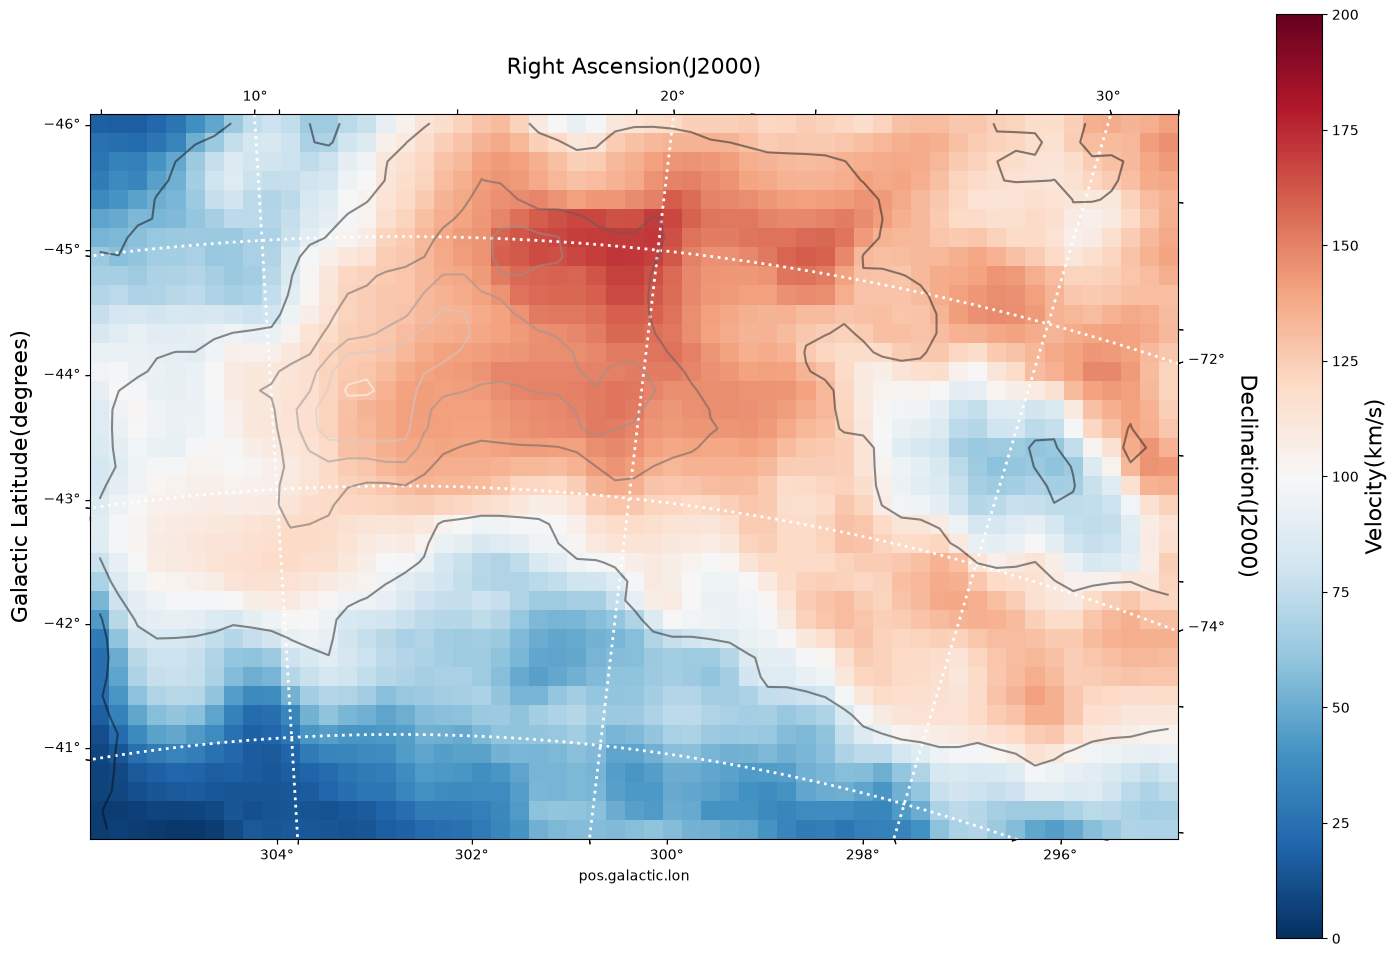

In [28]:
# Initiate a figure and axis object with WCS projection information
fig = plt.figure(figsize=(18,12))
ax= fig.add_subplot(111, projection=moment_1.wcs)

# Display the moment map image

im= ax.imshow(moment_1.hdu.data, cmap="RdBu_r", vmin=0, vmax=200)
ax.invert_yaxis() # Flips the Y axis

# Add axes labels
ax.set_xlabel("Galactic Longitude(degrees)", fontsize=16)
ax.set_ylabel("Galactic Latitude(degrees)",fontsize=16)

# Add a colorbar
cbar = plt.colorbar(im, pad=0.07)
cbar.set_label("Velocity(km/s)", size=16)

# Overlay set of RA/Dec Axes
overlay= ax.get_coords_overlay("fk5")
overlay.grid(color="white", ls="dotted", lw=2)
overlay[0].set_axislabel("Right Ascension(J2000)", fontsize=16)
overlay[1].set_axislabel("Declination(J2000)", fontsize=16)

# Overplt column density contours
# Contour levels
levels= (1e20, 5e20, 1e21, 3e21, 5e21, 7e21, 1e22)
ax.contour(hi_column_density.hdu.data, cmap="Greys_r", alpha=0.5, levels=levels)




WCSframework in astropy also lets us slice the data across different dimensions. It is often useful to slice along a single latitude and display an image showing longitude-velocity diagram.


We can do this by using slices keyword and selecting the appropriate slice through the data.

slices requires a 3D tuple containing the index to be sliced along 
and where we want the two axes to be displayed. This should be 
specified in the same order as the WCS object(longitude , latitude, velocity) as opposed to the order  of numpy array holding
the data(velocity, latitude, longitude). 

In [ ]:
# Displaying a longitude-velocity Slice


